**Task 5: Feature Engineering & EDA**

In [1]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

In [2]:
# Load dataset
df_clean = pd.read_csv('C:\\Users\\User\\Desktop\\PG230\\PG230_Bank_Loan_default_prediction\\results\\outputs\\Scaled_data.csv')

In [3]:
print("All columns in the dataset before feature engineering:")
print(df_clean.columns)

All columns in the dataset before feature engineering:
Index(['person_age', 'person_gender', 'person_income', 'person_emp_exp',
       'loan_amnt', 'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length', 'credit_score',
       'previous_loan_defaults_on_file', 'loan_status',
       'person_education_Bachelor', 'person_education_Doctorate',
       'person_education_High School', 'person_education_Master',
       'person_home_ownership_OTHER', 'person_home_ownership_OWN',
       'person_home_ownership_RENT', 'loan_intent_EDUCATION',
       'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL',
       'loan_intent_PERSONAL', 'loan_intent_VENTURE'],
      dtype='object')




* Debt-to income ratio measures the proportion of income used for the loan. It will help identify applicants with higher financial risk which will be valuable for predicting loan status.



In [4]:
# Debt-to-Income Ratio
df_clean['debt_to_income_ratio'] = df_clean['loan_amnt'] / df_clean['person_income']



* Age is divided into four categories (Young, Adult, Senior, Elder) for futher clarity. Then they are encoded using one-hot encoding.



In [5]:
# Age groups
bins = [18, 30, 50, 65, 100]
labels = ['Young','Adult','Senior','Elder']
df_clean['age_group'] = pd.cut(df_clean['person_age'], bins=bins, labels=labels)

In [6]:
# One-Hot Encode age_group
df_clean = pd.get_dummies(df_clean, columns=['age_group'], drop_first=True)

In [7]:
print("All columns in the dataset after feature engineering:")
print(df_clean.columns)

All columns in the dataset after feature engineering:
Index(['person_age', 'person_gender', 'person_income', 'person_emp_exp',
       'loan_amnt', 'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length', 'credit_score',
       'previous_loan_defaults_on_file', 'loan_status',
       'person_education_Bachelor', 'person_education_Doctorate',
       'person_education_High School', 'person_education_Master',
       'person_home_ownership_OTHER', 'person_home_ownership_OWN',
       'person_home_ownership_RENT', 'loan_intent_EDUCATION',
       'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL',
       'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'debt_to_income_ratio',
       'age_group_Adult', 'age_group_Senior', 'age_group_Elder'],
      dtype='object')




* A correlation heatmap is plotted to examin relationship between numeric features.


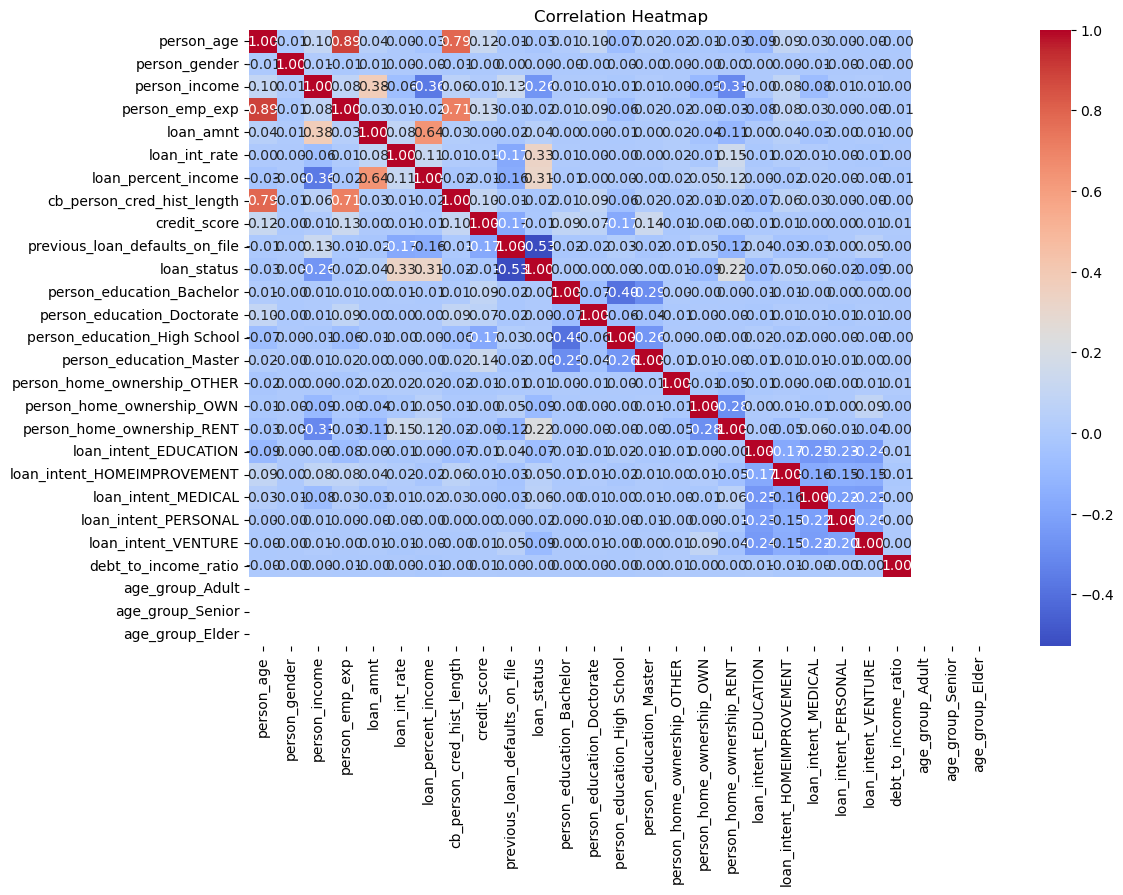

In [8]:
# Correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()



* We used a countplot to show how many applicants default and how many did not.








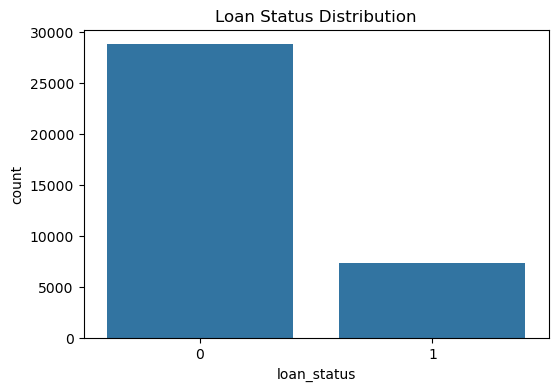

In [9]:
# Class balance
plt.figure(figsize=(6,4))
sns.countplot(x='loan_status', data=df_clean)
plt.title("Loan Status Distribution")
plt.show()

* We used a boxplot to quickly see if people who failed to pay back their loans (Defult) typically had more debt than people who paid them back (No defult).

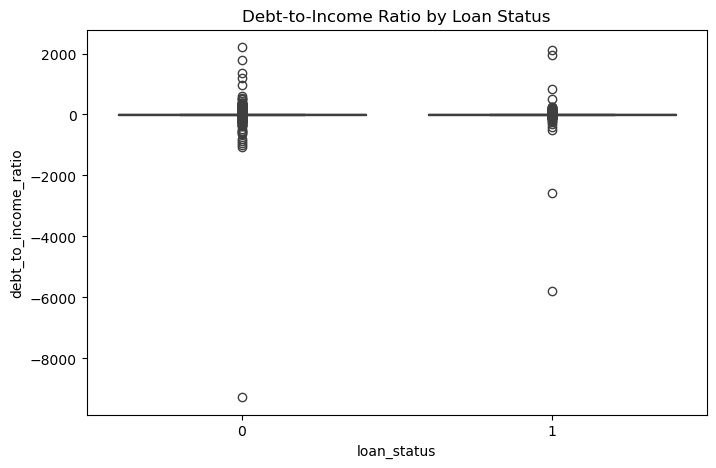

In [10]:
# Debt-to-Income vs Loan Status
plt.figure(figsize=(8,5))
sns.boxplot(x='loan_status', y='debt_to_income_ratio', data=df_clean)
plt.title("Debt-to-Income Ratio by Loan Status")
plt.show()

In [11]:
# Create a new DataFrame with new features
df_clean.to_csv('C:/Users/User/Desktop/PG230/PG230_Bank_Loan_default_prediction/results/outputs/new_featured_data.csv', index=False)